In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import zipfile
import urllib.request

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

urllib.request.urlretrieve(url, "sms_spam.zip")

with zipfile.ZipFile("sms_spam.zip", "r") as zip_ref:
    zip_ref.extractall("sms_dataset")

df = pd.read_csv(
    "sms_dataset/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print(df.head())
print("\nDataset shape:", df.shape)

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset shape: (5572, 2)


In [3]:
print("Dataset Information:")
print(df.info())

print("\nClass Distribution:")
print(df["label"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing Values:
label      0
message    0
dtype: int64


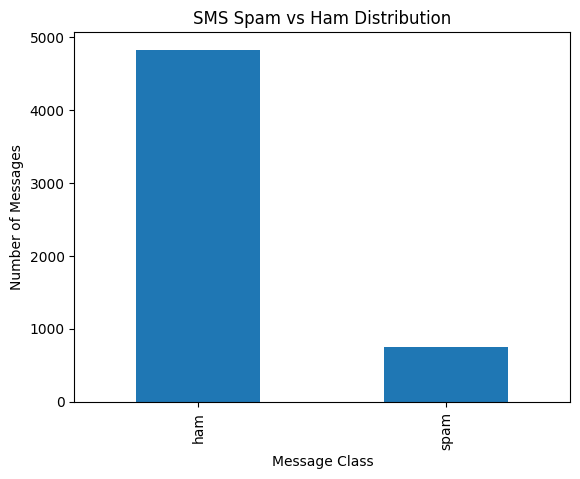

In [4]:
df["label"].value_counts().plot(
    kind="bar",
    title="SMS Spam vs Ham Distribution"
)

plt.xlabel("Message Class")
plt.ylabel("Number of Messages")
plt.show()

In [5]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df["clean_message"] = df["message"].apply(clean_text)

print(df[["message", "clean_message"]].head())

                                             message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                       clean_message  
0  go until jurong point crazy available only in ...  
1                            ok lar joking wif u oni  
2  free entry in a wkly comp to win fa cup final ...  
3        u dun say so early hor u c already then say  
4  nah i dont think he goes to usf he lives aroun...  


In [6]:
X = df["clean_message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training data:", X_train_tfidf.shape)
print("Testing data:", X_test_tfidf.shape)

Training data: (4457, 5000)
Testing data: (1115, 5000)


In [7]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute"
    ),

    "SVM": LinearSVC(
        random_state=42
    ),

    "Naive Bayes": MultinomialNB()
}

results = []
predictions = {}

for name, model in models.items():

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    predictions[name] = y_pred

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="spam"
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="spam"
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label="spam"
        )
    })

print("All four models trained successfully!")

All four models trained successfully!


In [8]:
results_df = pd.DataFrame(results)

print(results_df.round(4))

results_df.to_csv(
    "classification_results.csv",
    index=False
)

       Algorithm  Accuracy  Precision  Recall  F1-Score
0  Decision Tree    0.9507     0.8176  0.8121    0.8148
1            KNN    0.9668     0.9746  0.7718    0.8614
2            SVM    0.9830     0.9710  0.8993    0.9338
3    Naive Bayes    0.9668     1.0000  0.7517    0.8582


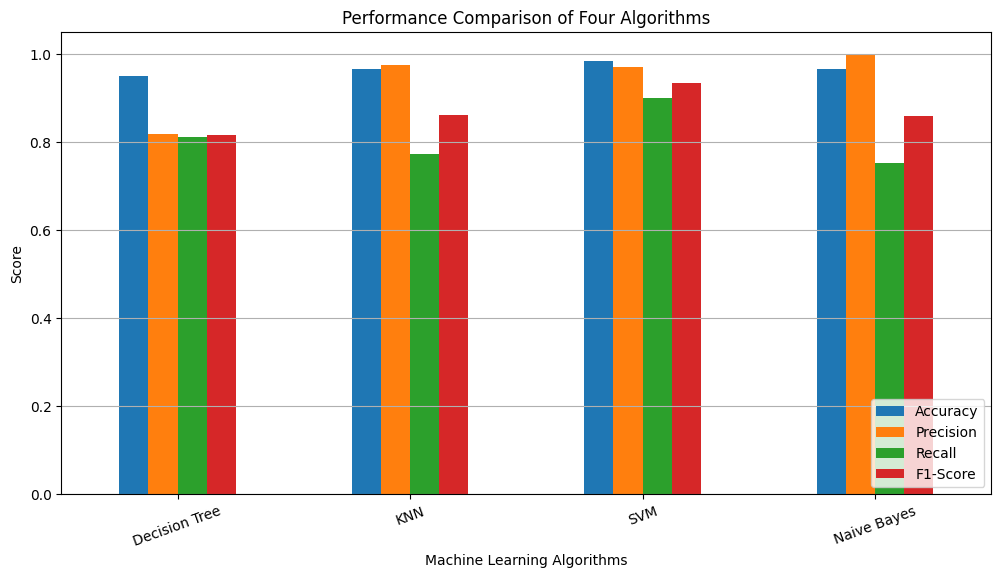

In [9]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

results_df.set_index("Algorithm")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Four Algorithms")
plt.ylabel("Score")
plt.xlabel("Machine Learning Algorithms")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()

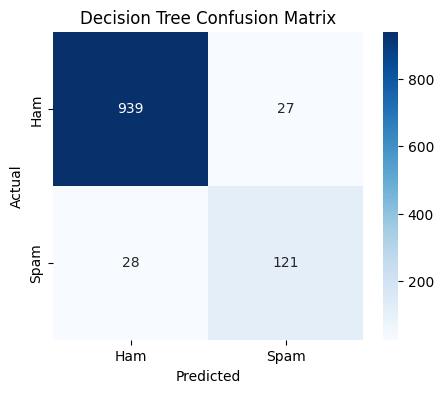

Decision Tree
              precision    recall  f1-score   support

         ham       0.97      0.97      0.97       966
        spam       0.82      0.81      0.81       149

    accuracy                           0.95      1115
   macro avg       0.89      0.89      0.89      1115
weighted avg       0.95      0.95      0.95      1115



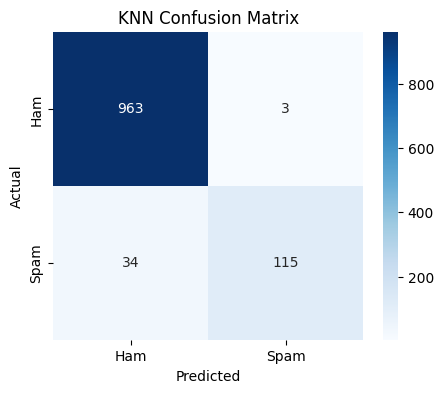

KNN
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       0.97      0.77      0.86       149

    accuracy                           0.97      1115
   macro avg       0.97      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115



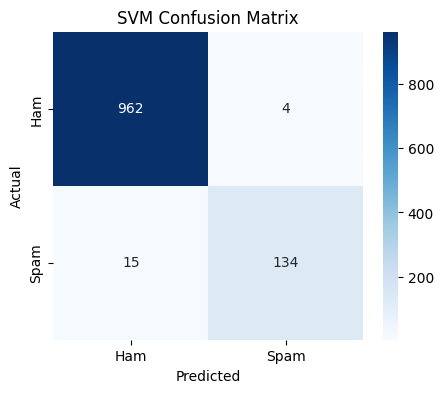

SVM
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       966
        spam       0.97      0.90      0.93       149

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



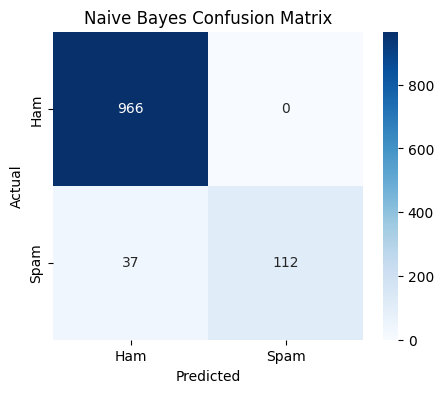

Naive Bayes
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.75      0.86       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.96      1115



In [10]:
for name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["ham", "spam"]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"]
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    print(name)
    print(classification_report(y_test, y_pred))

In [11]:
knn3 = KNeighborsClassifier(
    n_neighbors=3,
    metric="cosine",
    algorithm="brute"
)

knn3.fit(X_train_tfidf, y_train)

knn3_pred = knn3.predict(X_test_tfidf)

print("KNN with K=3")
print("Accuracy:", accuracy_score(y_test, knn3_pred))
print("Precision:", precision_score(
    y_test, knn3_pred, pos_label="spam"
))
print("Recall:", recall_score(
    y_test, knn3_pred, pos_label="spam"
))
print("F1 Score:", f1_score(
    y_test, knn3_pred, pos_label="spam"
))

print("\nKNN with K=5")
print("Accuracy:", accuracy_score(
    y_test, predictions["KNN"]
))

KNN with K=3
Accuracy: 0.9497757847533632
Precision: 0.8163265306122449
Recall: 0.8053691275167785
F1 Score: 0.8108108108108109

KNN with K=5
Accuracy: 0.9668161434977578


In [12]:
best_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("BEST PERFORMING MODEL")
print("----------------------")

print("Algorithm:", best_model["Algorithm"])
print("Accuracy:", best_model["Accuracy"])
print("Precision:", best_model["Precision"])
print("Recall:", best_model["Recall"])
print("F1 Score:", best_model["F1-Score"])

BEST PERFORMING MODEL
----------------------
Algorithm: SVM
Accuracy: 0.9829596412556054
Precision: 0.9710144927536232
Recall: 0.8993288590604027
F1 Score: 0.9337979094076655
